# Air Attacks: Exploratory Data Analysis
**Shaden Alrshoud**

# Step 1: Dataset

* **Title:** Massive Missile Attacks on Ukraine
* **Source:** Kaggle, by Petro Ivaniuk: https://www.kaggle.com/datasets/piterfm/massive-missile-attacks-on-ukraine

**Description:**
This dataset records the Russian missile and drone attacks on Ukraine from September 2022 to October 2026.
Each row is one attack with one weapon model, showing how many were launched and how many were destroyed by air defense.
It also includes the time of the attack, the target region and the launch place.

**Why I selected it:**
Missile and drone attacks are not just a news topic for us. Here in Riyadh, we are currently living with these threats, which made me want to understand them through data.
My first goal was to analyze real data about the attacks here on Saudi Arabia, but detailed public data about them (such as the number of weapons launched and intercepted) is not available.
So I chose this dataset, because it is one of the most detailed real and publicly available records of air attacks: it is based on official daily reports and covers four years of attacks with the same kinds of weapons, such as drones and ballistic missiles.
By studying it, I want to learn patterns that can also apply to our situation: how attacks grow, which weapons are the hardest to intercept, and whether large attacks overwhelm air defense.
These insights can help us better understand the challenges that air defense faces, and how can our country prepare for similar threats.

# Step 2: Problem Definition

### What is the dataset about?
This dataset records the Russian air attacks on Ukraine from **September 2022 to October 2026**, based on the official daily reports of the **Ukrainian Air Force**.
Each row represents one attack with one type of weapon (missile or drone). It includes the **date and time** of the attack, the **weapon model**, the **target region**, the **number launched**, and the **number destroyed (intercepted)** by air defense.
The dataset contains **4,285 records** and covers **88 different weapon models**.

### What main questions will we explore?
1. How has the number and scale of attacks changed over time?
2. Which weapon models are used most often?
3. What is the interception rate of each weapon model? Which weapons are the hardest to intercept?
4. Are large attacks intercepted at a lower rate than small attacks?
5. On which days of the week and in which months are attacks most frequent?
6. How has the use of Shahed drones (the most common weapon) changed over time, and how does it affect the overall interception rate?

### What insights do we expect to uncover?
* We expect the **number and size of attacks to increase strongly** over the years, especially since 2024.
* We expect **Shahed drones** to be the most used weapon and to make up a growing share of attacks over time.
* We expect **some weapons to be much harder to intercept**. Ballistic missiles (such as Iskander-M) should have lower interception rates than drones.
* We expect that **very large attacks may lower the interception rate**, because many weapons at once can overwhelm air defenses.
* We may find **seasonal patterns**, for example more attacks in certain months or on certain days.

### Key variable
This is an exploratory analysis, so there is no fixed target. Our main measure is the **interception rate**, which we will create:

**interception rate = destroyed ÷ launched × 100**

# Step 3: Data Loading & Structure

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("missile_attacks_daily.csv")
df.head()

,time_start,time_end,model,launch_place,target,target_main,status_data,launched,destroyed,not_reach_goal,...,num_fall_fragment_location,is_shahed,border_crossing,carrier,affected region,destroyed_types,destroyed_details,launched_details,launch_place_details,source
0,2026-10-23 18:00,2026-10-24 08:00,Shahed-136/131,Primorsko-Akhtarsk and Kursk oblast and Bryans...,Ukraine,NaN,NaN,126.0,101.0,0.0,...,5.0,NaN,{},NaN,NaN,"{'Turbojet': {'launched': 61, 'destroyed': 50}}","{'south': 11, 'east': NaN, 'north': NaN}",NaN,NaN,kpszsu/posts/pfbid02krpG8X8gHJgZtJuSAXHXZhxAjz...
1,2026-10-23 18:00,2026-10-24 08:00,Geran-4 and Geran-5,NaN,west,Rivne oblast and Volyn oblast and Khmelnytskyi...,NaN,43.0,43.0,NaN,...,NaN,NaN,{},NaN,NaN,NaN,NaN,NaN,NaN,PvkZahid/posts/pfbid02jSUHVi4cHwnWgLjaj2AsjQhp...
2,2026-10-22 18:00,2026-10-23 08:00,Shahed-136/131,Primorsko-Akhtarsk and Kursk oblast and Bryans...,Ukraine,NaN,NaN,176.0,140.0,0.0,...,13.0,NaN,{},NaN,NaN,"{'Turbojet': {'launched': 92, 'destroyed': 68}}","{'south': 37, 'east': NaN, 'north': NaN}",NaN,NaN,kpszsu/posts/pfbid035vtrJfou8Wu6D2AWsRSmsRamrw...
3,2026-10-22 18:00,2026-10-23 08:00,Geran-4 and Geran-5,NaN,west,Rivne oblast and Volyn oblast and Khmelnytskyi...,NaN,52.0,52.0,NaN,...,NaN,NaN,{},NaN,NaN,NaN,NaN,NaN,NaN,PvkZahid/posts/pfbid0euvwGUwU5mTczzYRF3KdcfUnA...
4,2026-10-23,2026-10-23,X-59/X-69,Crimea,south,NaN,NaN,1.0,0.0,NaN,...,NaN,NaN,{},NaN,NaN,NaN,NaN,NaN,NaN,PvKPivden/posts/pfbid04j17geDZg8oSiFodcFPucnfQ...


In [3]:
print("Shape:", df.shape)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Shape: (4285, 22)
Rows: 4285
Columns: 22


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4285 entries, 0 to 4284
Data columns (total 22 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   time_start                  4285 non-null   object 
 1   time_end                    4285 non-null   object 
 2   model                       4285 non-null   object 
 3   launch_place                2298 non-null   object 
 4   target                      4285 non-null   object 
 5   target_main                 151 non-null    object 
 6   status_data                 25 non-null     object 
 7   launched                    4282 non-null   float64
 8   destroyed                   4279 non-null   float64
 9   not_reach_goal              882 non-null    float64
 10  still_attacking             364 non-null    float64
 11  num_hit_location            523 non-null    float64
 12  num_fall_fragment_location  506 non-null    float64
 13  is_shahed                   239 n

In [5]:
df.describe()

,launched,destroyed,not_reach_goal,still_attacking,num_hit_location,num_fall_fragment_location,is_shahed
count,4282.000000,4279.000000,882.000000,364.000000,523.000000,506.000000,239.000000
mean,35.747781,28.108904,14.871882,3.282967,12.523901,5.144269,108.422594
std,77.962745,65.610385,33.104802,5.585266,6.885830,5.611951,78.166820
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,10.000000
25%,1.000000,1.000000,0.000000,0.000000,8.000000,1.000000,60.000000
50%,4.000000,3.000000,0.000000,2.000000,11.000000,4.000000,80.000000
75%,32.000000,26.000000,18.000000,4.000000,15.000000,7.000000,120.000000
max,810.000000,747.000000,415.000000,55.000000,54.000000,44.000000,400.000000


In [8]:
print("Missing value:")
df.isnull().sum()

Missing value:


,0
time_start,0
time_end,0
model,0
launch_place,1987
target,0
target_main,4134
status_data,4260
launched,3
destroyed,6
not_reach_goal,3403


In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("Number of weapon models:", df["model"].nunique())
print()
print(df["model"].value_counts().head(10))

Duplicate rows: 0
Number of weapon models: 88

model
Shahed-136/131        1207
Unknown UAV            459
Iskander-M             315
Orlan-10               201
Reconnaissance UAV     200
X-59                   180
Supercam               178
ZALA                   175
Lancet                 143
X-59/X-69              125
Name: count, dtype: int64


### Observations
* The dataset has **4,285 rows** and **22 columns**.
* Most columns are **text (object)**, including the dates, so `time_start` must be converted to a date.
* `time_start` is written in **two formats**: some rows only have a date (`2024-05-12`), and others have a date and time (`2024-05-12 18:00`).
* **13 columns are 76% – 99.8% empty** (for example `carrier`, `is_shahed`, `status_data`), so they cannot be used.
* The most important columns (`time_start`, `model`, `target`, `launched`, `destroyed`) are almost complete.
* There are **no duplicate rows**.
* There are **88 different weapon models**, and **Shahed-136/131** drones are by far the most common.

# Step 4: Data Cleaning

We make a copy of the original data and clean the copy.

### 1. Drop unneeded columns
We keep only the useful columns. The others are either **mostly empty** (more than 75% missing), or **not useful** for analysis (`source` is a link to the original post, and `border_crossing` is almost always empty `{}`).

In [9]:
keep_cols = ["time_start", "time_end", "model", "launch_place", "target", "launched", "destroyed"]
df_clean = df[keep_cols].copy()

print("Shape after dropping columns:", df_clean.shape)

Shape after dropping columns: (4285, 7)


### 2. Remove duplicates
The full dataset had no duplicates, but after keeping only 7 columns some rows may become identical.

In [10]:
print("Duplicate rows:", df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates()
print("Shape:", df_clean.shape)

Duplicate rows: 3
Shape: (4282, 7)


### 3. Convert data types
`time_start` and `time_end` are text in two different formats, so we use `format="mixed"` to convert both formats to dates.

In [11]:
df_clean["time_start"] = pd.to_datetime(df_clean["time_start"], format="mixed")
df_clean["time_end"] = pd.to_datetime(df_clean["time_end"], format="mixed")

print(df_clean[["time_start", "time_end"]].dtypes)

time_start    datetime64[ns]
time_end      datetime64[ns]
dtype: object


### 4. Handle missing values
* `launched` and `destroyed` are missing in only a few rows. We **drop** these rows, because we cannot calculate the interception rate without them.
* `launch_place` is missing in 46% of rows. Instead of dropping these rows, we fill them with **"Unknown"**.

In [12]:
print("Missing before:")
print(df_clean.isnull().sum())

df_clean = df_clean.dropna(subset=["launched", "destroyed"])
df_clean["launch_place"] = df_clean["launch_place"].fillna("Unknown")

print("\nMissing after:")
print(df_clean.isnull().sum())

Missing before:
time_start         0
time_end           0
model              0
launch_place    1985
target             0
launched           3
destroyed          6
dtype: int64

Missing after:
time_start      0
time_end        0
model           0
launch_place    0
target          0
launched        0
destroyed       0
dtype: int64


### 5. Remove impossible rows
Some rows have **launched = 0**. We cannot calculate an interception rate for them (division by zero), so we remove them.

In [13]:
print("Rows with launched = 0:", (df_clean["launched"] == 0).sum())
df_clean = df_clean[df_clean["launched"] > 0]

# launched and destroyed are counts, so we convert them to integers
df_clean["launched"] = df_clean["launched"].astype(int)
df_clean["destroyed"] = df_clean["destroyed"].astype(int)

print("Shape:", df_clean.shape)

Rows with launched = 0: 16
Shape: (4257, 7)


### 6. Rename columns

In [14]:
df_clean = df_clean.rename(columns={
    "time_start": "start_time",
    "time_end": "end_time",
    "model": "weapon_model"
})
print(df_clean.columns.tolist())

['start_time', 'end_time', 'weapon_model', 'launch_place', 'target', 'launched', 'destroyed']


### 7. Create new columns
We create new columns that help answer our questions:
* **year, month, day_of_week**: from the start time
* **interception_rate**: destroyed ÷ launched × 100
* **is_shahed**: whether the weapon is a Shahed drone

In [15]:
df_clean["year"] = df_clean["start_time"].dt.year
df_clean["month"] = df_clean["start_time"].dt.month
df_clean["day_of_week"] = df_clean["start_time"].dt.day_name()

df_clean["interception_rate"] = (df_clean["destroyed"] / df_clean["launched"] * 100).round(1)
df_clean["is_shahed"] = df_clean["weapon_model"].str.contains("Shahed")

df_clean.head()

,start_time,end_time,weapon_model,launch_place,target,launched,destroyed,year,month,day_of_week,interception_rate,is_shahed
0,2026-10-23 18:00:00,2026-10-24 08:00:00,Shahed-136/131,Primorsko-Akhtarsk and Kursk oblast and Bryans...,Ukraine,126,101,2026,10,Friday,80.2,True
1,2026-10-23 18:00:00,2026-10-24 08:00:00,Geran-4 and Geran-5,Unknown,west,43,43,2026,10,Friday,100.0,False
2,2026-10-22 18:00:00,2026-10-23 08:00:00,Shahed-136/131,Primorsko-Akhtarsk and Kursk oblast and Bryans...,Ukraine,176,140,2026,10,Thursday,79.5,True
3,2026-10-22 18:00:00,2026-10-23 08:00:00,Geran-4 and Geran-5,Unknown,west,52,52,2026,10,Thursday,100.0,False
4,2026-10-23 00:00:00,2026-10-23 00:00:00,X-59/X-69,Crimea,south,1,0,2026,10,Friday,0.0,False


### 8. Save the cleaned data

In [16]:
df_clean.to_csv("clean_data.csv", index=False)
print("Saved clean_data.csv with shape:", df_clean.shape)

Saved clean_data.csv with shape: (4257, 12)


### Cleaning Summary

| Step | Action | Result |
|---|---|---|
| Drop columns | Removed 15 mostly-empty or unneeded columns | 22 → 7 columns |
| Duplicates | Removed duplicate rows (after keeping 7 columns) | 3 removed |
| Data types | Converted the times from text to dates | Dates ready for analysis |
| Missing values | Dropped rows with no launched/destroyed; filled launch_place with "Unknown" | 0 missing |
| Impossible rows | Removed rows with launched = 0 | Rate can be calculated |
| Rename | Clearer column names | Easier to read |
| New columns | year, month, day_of_week, interception_rate, is_shahed | Ready for EDA |
| Save | `clean_data.csv` | 4,257 rows, 12 columns |

# Step 5: Exploratory Data Analysis (EDA)

**Note on the interception rate:** when we compare groups (years, weapons), we calculate the rate as
**total destroyed ÷ total launched** for the group. This way a large attack of 500 drones counts more than an attack of 1 missile.

## Univariate Analysis

### 1. Histogram: attack size (number launched)

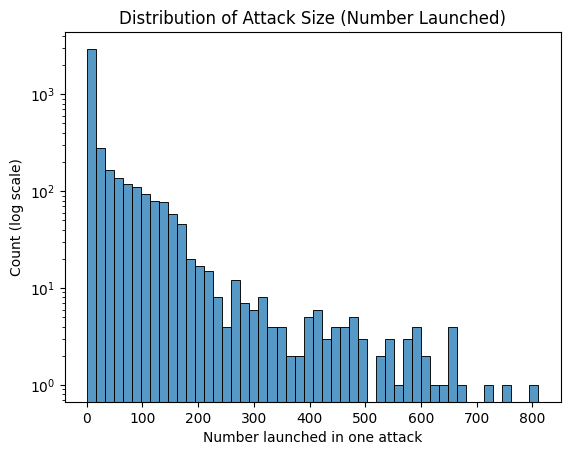

Median attack size: 4.0
Largest attack: 810


In [17]:
sns.histplot(df_clean["launched"], bins=50)
plt.yscale("log")
plt.title("Distribution of Attack Size (Number Launched)")
plt.xlabel("Number launched in one attack")
plt.ylabel("Count (log scale)")
plt.show()

print("Median attack size:", df_clean["launched"].median())
print("Largest attack:", df_clean["launched"].max())

**Insights:**
* The attack size is **extremely right-skewed**: the median attack is only **4 weapons**, but the largest attack had **810**.
* We used a **log scale** on the y-axis, otherwise the few very large attacks would be invisible.
* Most rows are small attacks (1–5 weapons), but the few large attacks contain most of the weapons launched.

### 2. Histogram: interception rate

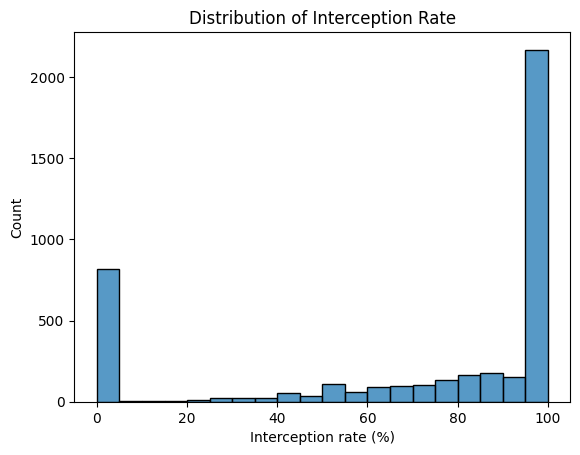

Attacks with 100% interception: 49.8 %
Attacks with 0% interception: 19.2 %


In [18]:
sns.histplot(df_clean["interception_rate"], bins=20)
plt.title("Distribution of Interception Rate")
plt.xlabel("Interception rate (%)")
plt.show()

print("Attacks with 100% interception:", round((df_clean["interception_rate"] == 100).mean() * 100, 1), "%")
print("Attacks with 0% interception:", round((df_clean["interception_rate"] == 0).mean() * 100, 1), "%")

**Insights:**
* The rate is concentrated at the two extremes: about **half of all attacks (49.8%) were fully intercepted (100%)**, and about **19% had 0%**.
* Values in between come mostly from large attacks, where some weapons were destroyed and some were not.
* This happens because many rows are small attacks (1–2 weapons), where the result can only be all or nothing.

### 3. Countplot: number of attacks per year

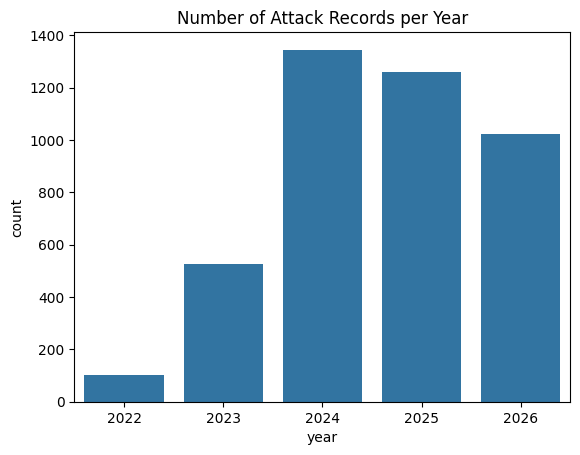

In [19]:
sns.countplot(x="year", data=df_clean)
plt.title("Number of Attack Records per Year")
plt.show()

**Insights:**
* The number of attack records grew from about 100 in 2022 to more than **1,300 in 2024**.
* 2022 only covers September–December, and 2026 only covers January–October, so those years are **incomplete**.

### 4. Boxplot: interception rate

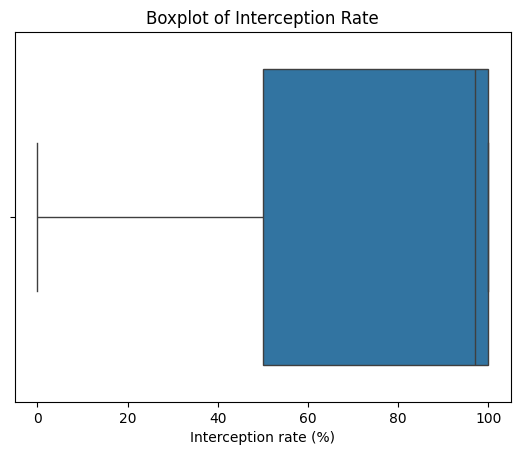

In [20]:
sns.boxplot(x=df_clean["interception_rate"])
plt.title("Boxplot of Interception Rate")
plt.xlabel("Interception rate (%)")
plt.show()

**Insights:**
* The median rate is about **97%**, and the middle 50% of attacks are between **50% and 100%**.
* The low values (close to 0%) are not errors. They are mostly weapons that are very hard to intercept, which we study in question 3.

## Bivariate & Multivariate Analysis

### 5. Attacks over time (Question 1)

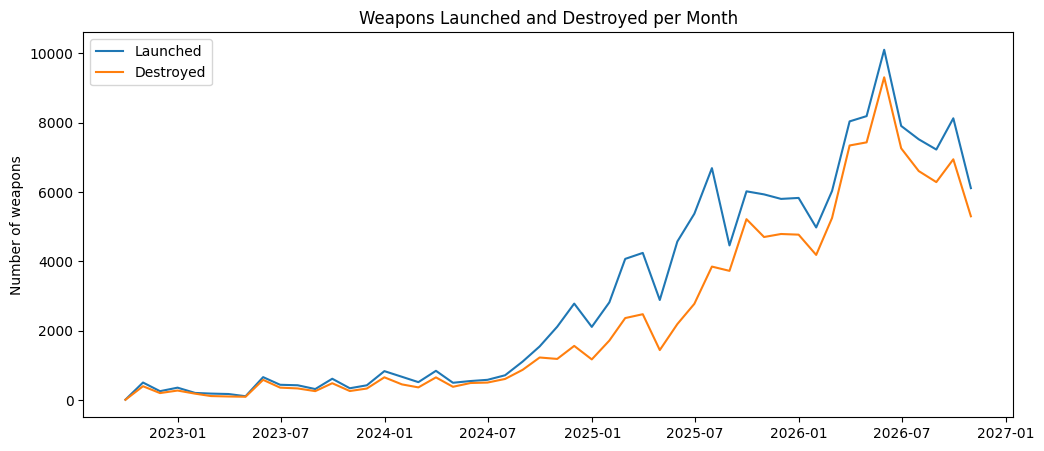

In [21]:
monthly = df_clean.set_index("start_time").resample("ME")[["launched", "destroyed"]].sum()

plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly["launched"], label="Launched")
plt.plot(monthly.index, monthly["destroyed"], label="Destroyed")
plt.title("Weapons Launched and Destroyed per Month")
plt.ylabel("Number of weapons")
plt.legend()
plt.show()

In [22]:
yearly = df_clean.groupby("year")[["launched", "destroyed"]].sum()
yearly["interception_rate"] = (yearly["destroyed"] / yearly["launched"] * 100).round(1)
print(yearly)

      launched  destroyed  interception_rate
year                                        
2022      1157        909               78.6
2023      4814       3845               79.9
2024     14109       9551               67.7
2025     58714      40058               68.2
2026     74212      65911               88.8


**Insights:**
* The scale of attacks **grew enormously**: from about **1,200 weapons in 2022** to **58,700 in 2025** and **74,200 in 2026** (with 2026 not yet complete).
* The biggest jump started in **2025**, when monthly totals reached several thousand weapons.
* The interception rate **dropped to about 68% in 2024–2025**, then rose to **almost 89% in 2026**.
* The highest month was in **mid-2026**, with about **10,000 weapons launched** in a single month.

### 6. Most used weapon models (Question 2)

weapon_model
Shahed-136/131            127348
Unknown UAV                14110
X-101/X-555                 2202
Молнія                       811
X-101/X-555 and Kalibr       704
Kalibr                       614
Iskander-M                   596
Reconnaissance UAV           460
C-400 and Iskander-M         396
Iskander-M/KN-23             372
Name: launched, dtype: int64


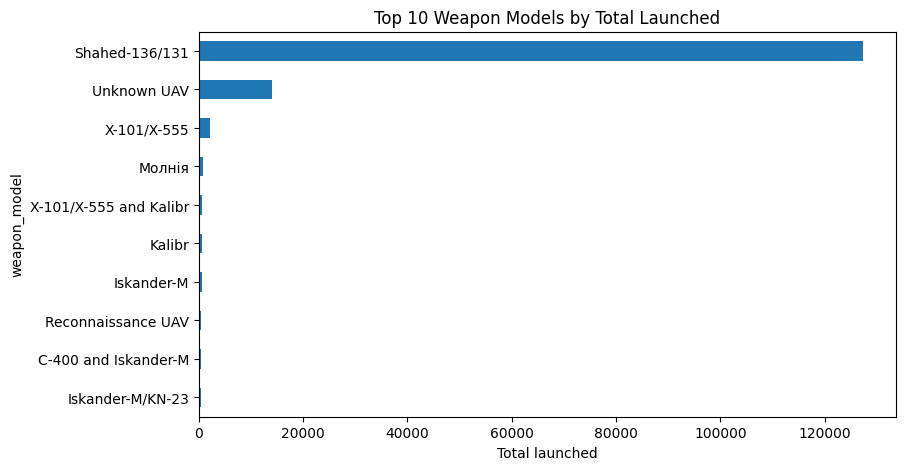

In [23]:
top_models = df_clean.groupby("weapon_model")["launched"].sum().sort_values(ascending=False).head(10)
print(top_models)

top_models.sort_values().plot(kind="barh", figsize=(9, 5))
plt.title("Top 10 Weapon Models by Total Launched")
plt.xlabel("Total launched")
plt.show()

**Insights:**
* **Shahed-136/131 drones dominate**: about **127,000 launched**, almost 9 times more than the second model.
* So the air war is mainly a **drone war** in terms of numbers.

### 7. Interception rate by weapon model (Question 3)

We only include weapon models with **at least 50 attacks**, so the rates are reliable.

                    attacks  launched  destroyed  interception_rate
weapon_model                                                       
C-300                    78       345          2                0.6
X-31P                    65       117          4                3.4
Iskander-M              314       596         87               14.6
Iskander-M/KN-23         84       372         97               26.1
X-47 Kinzhal             74       233         64               27.5
X-59                    180       331        201               60.7
Iskander-K               63       230        151               65.7
X-59/X-69               124       342        226               66.1
Shahed-136/131         1207    127348      98143               77.1
Kalibr                   83       614        478               77.9
X-101/X-555             109      2202       1907               86.6
Orlan-10                199       263        262               99.6
Supercam                178       252        251

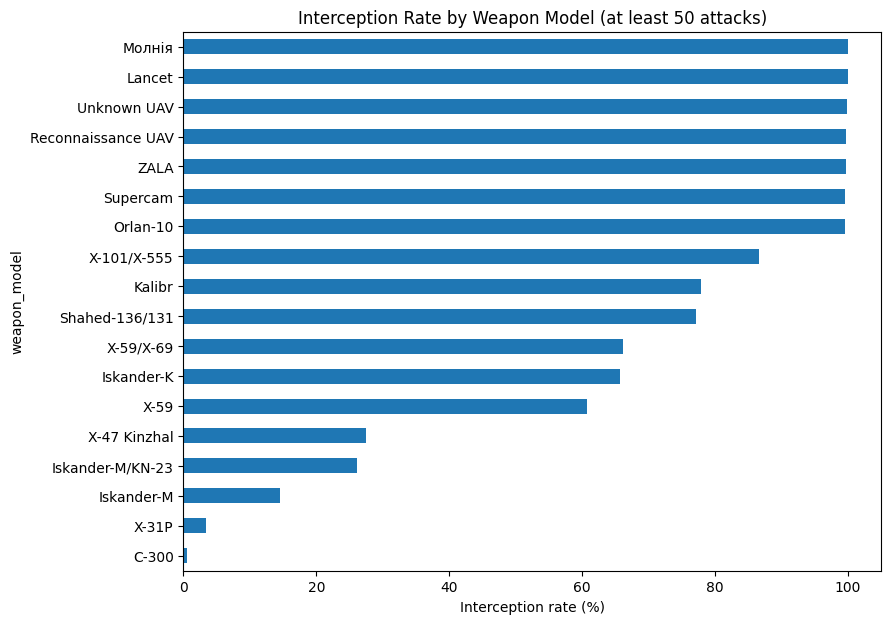

In [24]:
model_stats = df_clean.groupby("weapon_model").agg(
    attacks=("weapon_model", "size"),
    launched=("launched", "sum"),
    destroyed=("destroyed", "sum"))
model_stats["interception_rate"] = (model_stats["destroyed"] / model_stats["launched"] * 100).round(1)

common = model_stats[model_stats["attacks"] >= 50].sort_values("interception_rate")
print(common)

common["interception_rate"].plot(kind="barh", figsize=(9, 7))
plt.title("Interception Rate by Weapon Model (at least 50 attacks)")
plt.xlabel("Interception rate (%)")
plt.show()

**Insights:**
* The hardest weapons to intercept are **C-300 (0.6%)**, **X-31P (3.4%)**, **Iskander-M (14.6%)** and **X-47 Kinzhal (27.5%)**. These are fast **ballistic or high-speed missiles**.
* Most **drones** (Lancet, Orlan-10, reconnaissance UAVs) are intercepted at almost **100%**.
* **Shahed drones** have a **77%** rate. Lower than other drones, but they are launched in huge numbers.
* This confirms our expectation: **ballistic missiles are much harder to stop than drones**.

### 8. Attack size vs interception rate (Question 4)

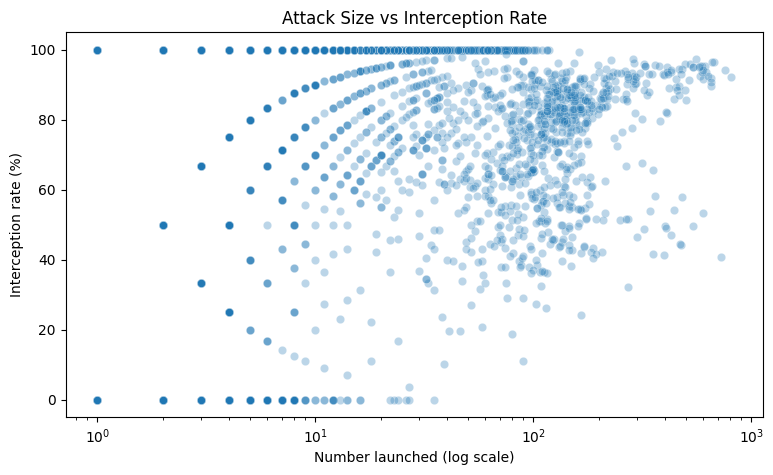

In [25]:
plt.figure(figsize=(9, 5))
sns.scatterplot(x="launched", y="interception_rate", data=df_clean, alpha=0.3)
plt.xscale("log")
plt.title("Attack Size vs Interception Rate")
plt.xlabel("Number launched (log scale)")
plt.ylabel("Interception rate (%)")
plt.show()

             launched  destroyed  interception_rate
attack_size                                        
1-5              4750       3132               65.9
6-20             6801       5374               79.0
21-50           12688      10639               83.9
51-100          27277      21253               77.9
100+           101490      79876               78.7


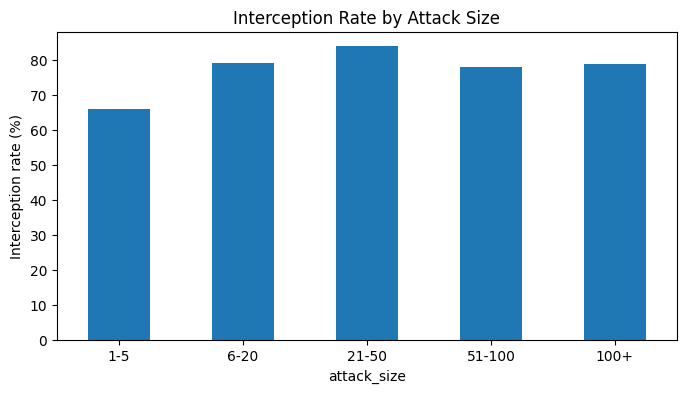

In [26]:
df_clean["attack_size"] = pd.cut(df_clean["launched"], bins=[0, 5, 20, 50, 100, 1000],
                                 labels=["1-5", "6-20", "21-50", "51-100", "100+"])

size_stats = df_clean.groupby("attack_size", observed=True)[["launched", "destroyed"]].sum()
size_stats["interception_rate"] = (size_stats["destroyed"] / size_stats["launched"] * 100).round(1)
print(size_stats)

size_stats["interception_rate"].plot(kind="bar", figsize=(8, 4))
plt.title("Interception Rate by Attack Size")
plt.ylabel("Interception rate (%)")
plt.xticks(rotation=0)
plt.show()

**Insights:**
* Large attacks are **not** intercepted at a lower rate. Attacks of **21–50 weapons have the highest rate (83.9%)**, and attacks of **100+ still have 78.7%**.
* The **lowest rate is for small attacks of 1–5 weapons (66%)**. These are often single ballistic missiles, which are hard to intercept.
* So the **type of weapon matters more than the size of the attack**. This was a surprising result, because we expected large attacks to overwhelm air defense.

### 9. Attacks by day of week and month (Question 5)

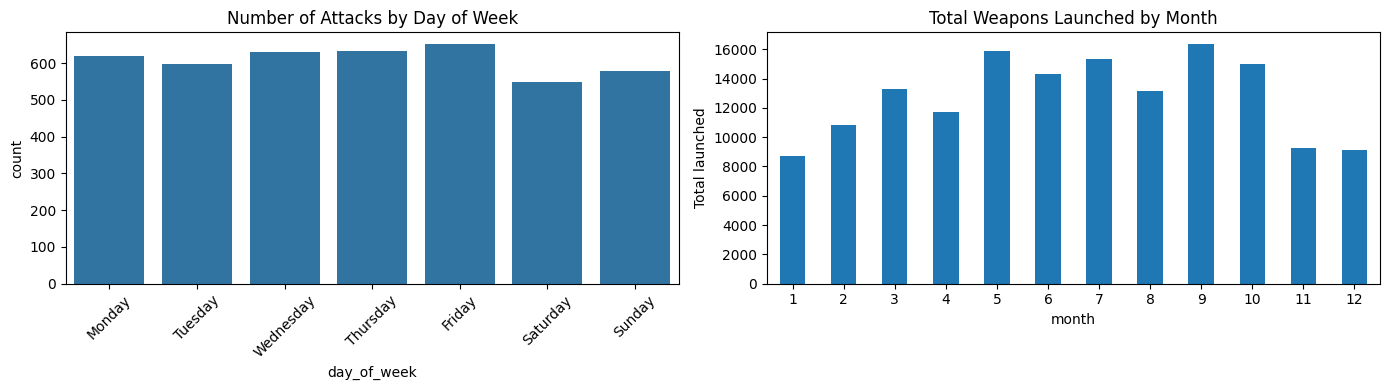

In [27]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.countplot(x="day_of_week", data=df_clean, order=day_order, ax=axes[0])
axes[0].set_title("Number of Attacks by Day of Week")
axes[0].tick_params(axis="x", rotation=45)

df_clean.groupby("month")["launched"].sum().plot(kind="bar", ax=axes[1])
axes[1].set_title("Total Weapons Launched by Month")
axes[1].set_ylabel("Total launched")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Insights:**
* **Day of week:** attacks are spread almost evenly, from about 550 (Saturday) to 650 (Friday). There is **no strong weekly pattern**.
* **Month:** the most weapons were launched in **September (16,300)** and **May (15,900)**, and the fewest in **January (8,700)**, **November** and **December** (about 9,000–9,300).
* The month comparison is affected by the **growth over the years**: months in 2025–2026 have many more weapons than months in 2022–2023.

### 10. Shahed drones over time (Question 6)

      Other weapons  Shahed  Shahed share (%)
year                                         
2022            748     409              35.4
2023           1691    3123              64.9
2024           3028   11081              78.5
2025           3918   54796              93.3
2026          16257   57955              78.1


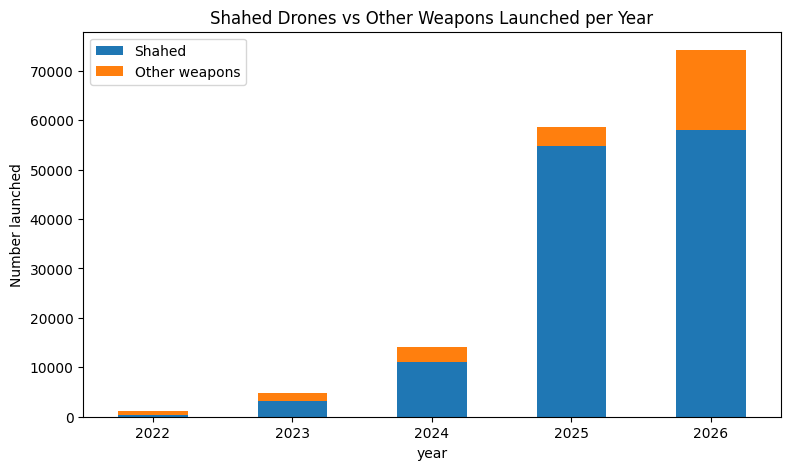

In [28]:
shahed_year = df_clean.groupby(["year", "is_shahed"])["launched"].sum().unstack()
shahed_year.columns = ["Other weapons", "Shahed"]
shahed_year["Shahed share (%)"] = (shahed_year["Shahed"] / shahed_year.sum(axis=1) * 100).round(1)
print(shahed_year)

shahed_year[["Shahed", "Other weapons"]].plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Shahed Drones vs Other Weapons Launched per Year")
plt.ylabel("Number launched")
plt.xticks(rotation=0)
plt.show()

      Other weapons  Shahed
year                       
2022           69.4    95.4
2023           72.6    83.8
2024           66.0    68.2
2025           77.6    67.6
2026           94.3    87.3


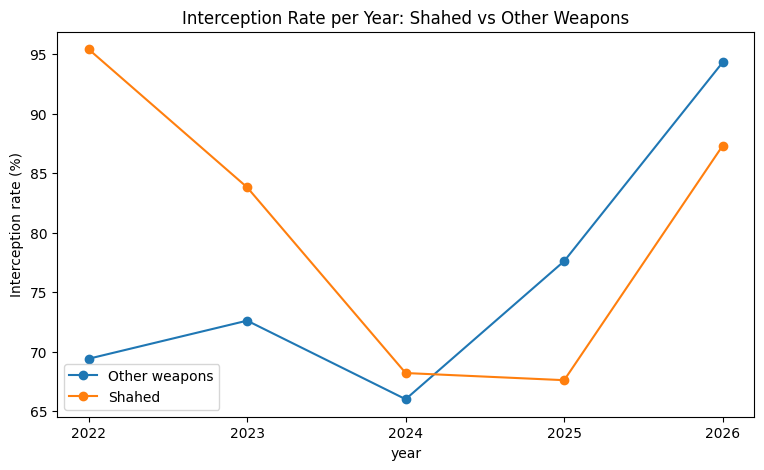

In [29]:
rate_type = df_clean.groupby(["year", "is_shahed"])[["launched", "destroyed"]].sum()
rate_type["interception_rate"] = (rate_type["destroyed"] / rate_type["launched"] * 100).round(1)
rate_type = rate_type["interception_rate"].unstack()
rate_type.columns = ["Other weapons", "Shahed"]
print(rate_type)

rate_type.plot(marker="o", figsize=(9, 5))
plt.xticks(rate_type.index)
plt.title("Interception Rate per Year: Shahed vs Other Weapons")
plt.ylabel("Interception rate (%)")
plt.show()

**Extra check:** the original data has a column `not_reach_goal`, which counts Shahed drones that were **lost** (for example by electronic jamming) instead of being shot down. We dropped it because it is mostly empty, but it helps explain the results:

In [30]:
check = df[df["model"].str.contains("Shahed")].copy()
check["year"] = pd.to_datetime(check["time_start"], format="mixed").dt.year
print(check.groupby("year")[["launched", "destroyed", "not_reach_goal"]].sum())

      launched  destroyed  not_reach_goal
year                                     
2022     409.0      390.0             0.0
2023    3123.0     2617.0             0.0
2024   11081.0     7552.0          2737.0
2025   54796.0    37016.0         10211.0
2026   57955.0    50578.0             0.0


**Insights:**
* The share of **Shahed drones grew from 35% of all weapons in 2022 to 93% in 2025**, then dropped to 78% in 2026.
* In 2022 Shaheds were intercepted at **95%**, but the rate fell to about **68% in 2024–2025**, then recovered to **87% in 2026**.
* In 2024–2025, Ukraine also reported **thousands of Shaheds as "lost"** (2,737 in 2024 and 10,211 in 2025), which are not counted as "destroyed".
* So the lower rate does **not** mean those drones all hit their targets. Many were stopped by **electronic warfare** instead of being shot down.

### 11. Correlation heatmap

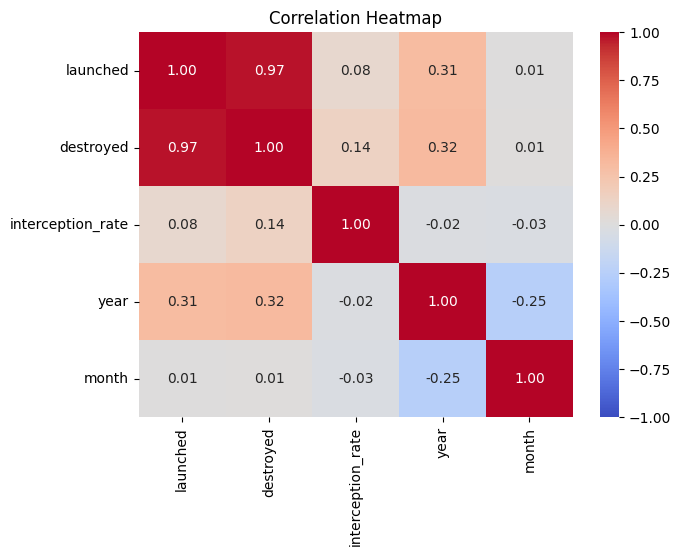

In [31]:
corr_cols = ["launched", "destroyed", "interception_rate", "year", "month"]

plt.figure(figsize=(7, 5))
sns.heatmap(df_clean[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

**Insights:**
* **launched and destroyed** are very strongly related (**0.97**): bigger attacks mean more weapons destroyed.
* **interception_rate** has almost **no relationship with attack size** (0.08). This confirms question 4: big attacks are not intercepted worse.
* **year** is positively related to launched (**0.31**): attacks get bigger over time.
* **month** has almost no relationship with the other variables.

# Step 6: Insights Summary

**Patterns discovered**
* The air war **grew dramatically**: from about 1,200 weapons launched in 2022 to more than **58,000 in 2025** and **74,000 in 2026**.
* It has become mainly a **drone war**: Shahed drones grew from **35% to 93%** of all weapons launched (2022 → 2025).
* There is **no strong weekly pattern**, and the monthly totals are mostly shaped by the growth over the years.

**Interesting relationships**
* **The type of weapon decides the interception rate, not the size of the attack.** Ballistic missiles (Iskander-M 14.6%, Kinzhal 27.5%, C-300 0.6%) are very hard to stop, while most drones are intercepted at almost 100%.
* **Large attacks are not intercepted worse.** Attacks of 21–50 weapons had the highest rate (83.9%), and the lowest rate was for small attacks of 1–5 weapons (66%).

**Outliers**
* The largest attack had **810 Shahed drones** (September 2025), while the median attack had only 4 weapons.
* Very low interception rates (close to 0%) are real, not errors: they belong to weapons that are hard to intercept.

**Key takeaways**
* Overall, about **79%** of all weapons were intercepted.
* The drop in the interception rate in 2024–2025 is partly explained by drones **lost to electronic warfare**, which are reported separately from "destroyed".
* Air defense is **very effective against drones**, but **ballistic missiles remain the biggest challenge**.